# Lab 1 – podstawowa analiza obrazu

W tym ćwiczeniu samodzielnie przeprowadzisz podstawową analizę obrazu cyfrowego z wykorzystaniem biblioteki `scikit-image`.

Twoim celem jest przejście przez cały prosty proces analizy:

**wczytanie obrazu → sprawdzenie jego właściwości → analiza kanałów → skala szarości → histogram → normalizacja → wyrównanie histogramu**


## 1. Wybierz obraz

Wybierz jeden obraz z wbudowanej bazy:

```python
skimage.data
```

Możesz wykorzystać np.:

```python
data.camera()
data.coins()
data.chelsea()
data.coffee()
data.horse()
data.moon()
data.rocket()
```

Nie wybieraj obrazu `astronaut`, ponieważ był już analizowany podczas zajęć.

Wyświetl wybrany obraz.


/var/folders/nl/tfyypr2x3b32jgs1y0mhj8cr0000gn/T/ipykernel_93746/2801653777.py:7: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(img)


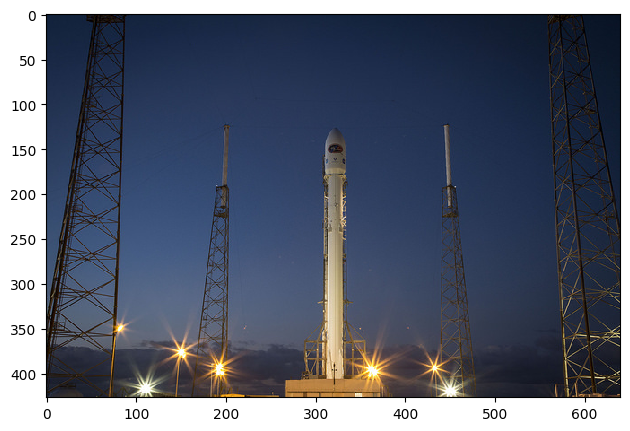

In [10]:
from skimage import data, color, exposure, img_as_float, io
import numpy as np
import matplotlib.pyplot as plt

# Wczytaj wybrany obraz
img = data.rocket()
io.imshow(img)


## 2. Sprawdź podstawowe informacje o obrazie

Sprawdź:

```python
img.shape
img.dtype
img.min()
img.max()
```

Zwróć uwagę na:

- wymiary obrazu,
- liczbę kanałów,
- typ danych,
- minimalną i maksymalną wartość pikseli.

### Zastanów się

Co informacje zwracane przez `shape` mówią o obrazie?  
Czy wartości pikseli są zapisane w zakresie `0–255`, czy `0–1`?


In [8]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())

# RGB
# range 0-255


Wymiary obrazu: (427, 640, 3)
Typ danych: uint8
Minimalna wartość: 0
Maksymalna wartość: 255


## 3. Określ rodzaj obrazu

Na podstawie wymiarów określ, czy obraz jest:

- obrazem w skali szarości,
- obrazem RGB,
- obrazem RGBA.

Przykładowo:

```text
(wysokość, szerokość)
```

oznacza zazwyczaj obraz w skali szarości,

natomiast:

```text
(wysokość, szerokość, 3)
```

oznacza obraz RGB.


## 4. Przeanalizuj kanały obrazu

Jeżeli wybrany obraz jest obrazem RGB, wydziel jego trzy kanały:

- R – czerwony,
- G – zielony,
- B – niebieski.

Wyświetl obok siebie:

**obraz RGB | kanał R | kanał G | kanał B**

Kanały możesz wyświetlić w skali szarości, ponieważ wtedy jasność piksela pokazuje intensywność danego kanału.

### Zastanów się

W których fragmentach obrazu poszczególne kanały są najjaśniejsze?  
Czy da się powiązać to z kolorami widocznymi na obrazie oryginalnym?

Jeśli obraz jest już w skali szarości, pomiń ten etap.


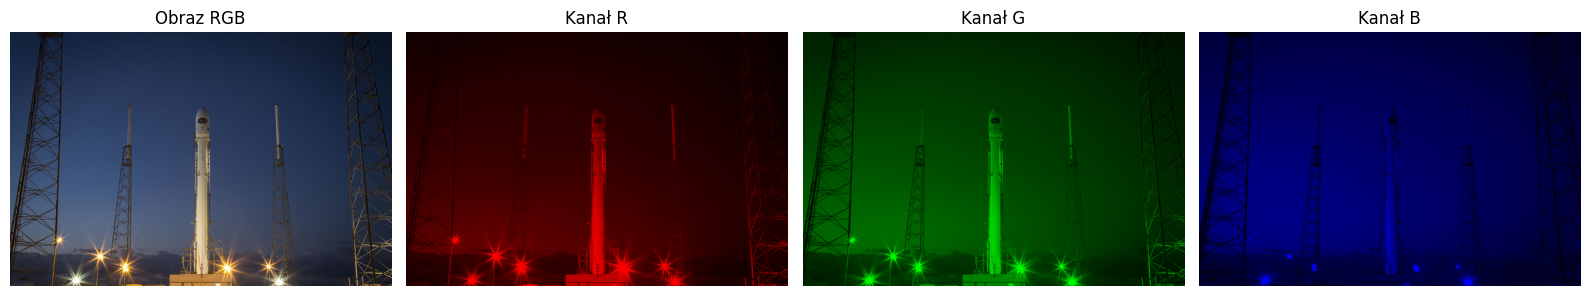

In [12]:
# Jeśli obraz jest RGB, wyświetl jego kanały R, G i B

# Kanał czerwony
red = np.zeros_like(img)
red[:, :, 0] = img[:, :, 0]

# Kanał zielony
green = np.zeros_like(img)
green[:, :, 1] = img[:, :, 1]

# Kanał niebieski
blue = np.zeros_like(img)
blue[:, :, 2] = img[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img)
axes[0].set_title("Obraz RGB")
axes[0].axis("off")

axes[1].imshow(red)
axes[1].set_title("Kanał R")
axes[1].axis("off")

axes[2].imshow(green)
axes[2].set_title("Kanał G")
axes[2].axis("off")

axes[3].imshow(blue)
axes[3].set_title("Kanał B")
axes[3].axis("off")

plt.tight_layout()
plt.show()


## 5. Przekonwertuj obraz do skali szarości

Jeżeli obraz jest kolorowy, przekonwertuj go do skali szarości:

```python
gray = color.rgb2gray(img)
```

Wyświetl obraz przed i po konwersji.

Ponownie sprawdź:

```python
gray.shape
gray.dtype
gray.min()
gray.max()
```

### Zastanów się

Co zmieniło się w strukturze danych po usunięciu informacji o kolorze?


/var/folders/nl/tfyypr2x3b32jgs1y0mhj8cr0000gn/T/ipykernel_93746/3020772719.py:3: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(gray)


Shape: (427, 640, 3)
Data type: uint8
Min value: 0
Max value: 255


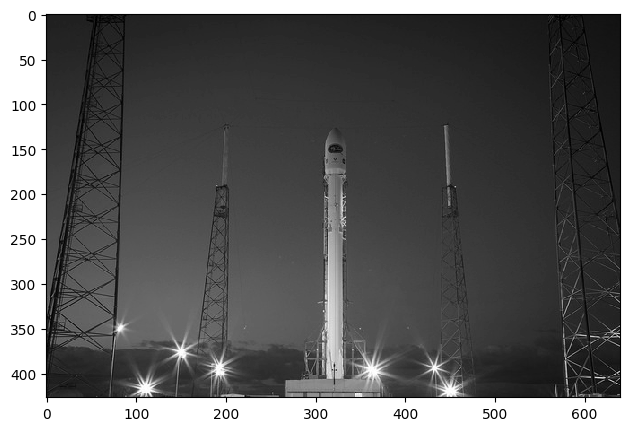

In [15]:
# Utwórz obraz w skali szarości
gray = color.rgb2gray(img)
io.imshow(gray)

print("Shape:", img.shape)
print("Data type:", img.dtype)
print("Min value:", img.min())
print("Max value:", img.max())

## 6. Narysuj histogram jasności

Dla obrazu w skali szarości utwórz histogram.

Użyj:

```python
bins=256
```

Pamiętaj, aby zakres histogramu odpowiadał zakresowi wartości pikseli.

Dla obrazu w zakresie `0–1`:

```python
range=(0, 1)
```

Dla obrazu w zakresie `0–255`:

```python
range=(0, 255)
```

Podpisz osie:

- oś X – poziom jasności,
- oś Y – liczba pikseli.

### Zastanów się

Czy większość pikseli znajduje się w obszarze ciemnych, średnich czy jasnych wartości?  
Czy histogram wykorzystuje szeroki zakres intensywności, czy wartości są skupione w niewielkim obszarze?


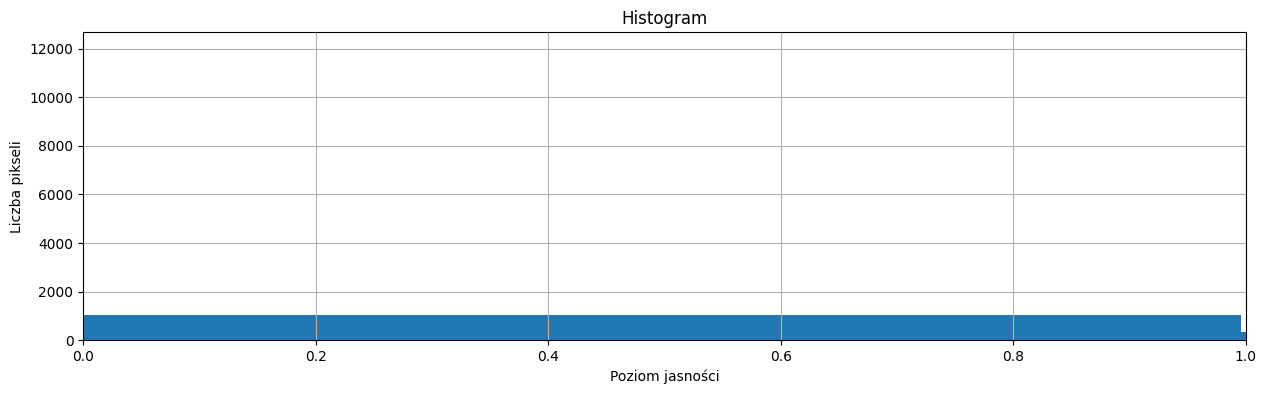

In [21]:
# Narysuj histogram obrazu w skali szarości
fig, axes = plt.subplots(1, 1, figsize=(15, 4))

axes.hist(img.ravel(), bins=256, range=(0, 255))
axes.set_title('Histogram')
axes.set_xlabel('Poziom jasności')
axes.set_ylabel('Liczba pikseli')
axes.set_xlim(0, 1)
axes.grid()


## 7. Wykonaj normalizację

Wykonaj normalizację obrazu za pomocą:

```python
exposure.rescale_intensity()
```

Przeskaluj wartości pikseli do zakresu:

```text
0–1
```

Wyświetl:

**obraz przed normalizacją | obraz po normalizacji**

Narysuj również histogramy obu obrazów.

### Zastanów się

Czy zakres wartości został rozciągnięty?  
Czy kontrast obrazu zmienił się zauważalnie?  
Jeżeli zmiana jest niewielka, spróbuj wyjaśnić, z czego może to wynikać.


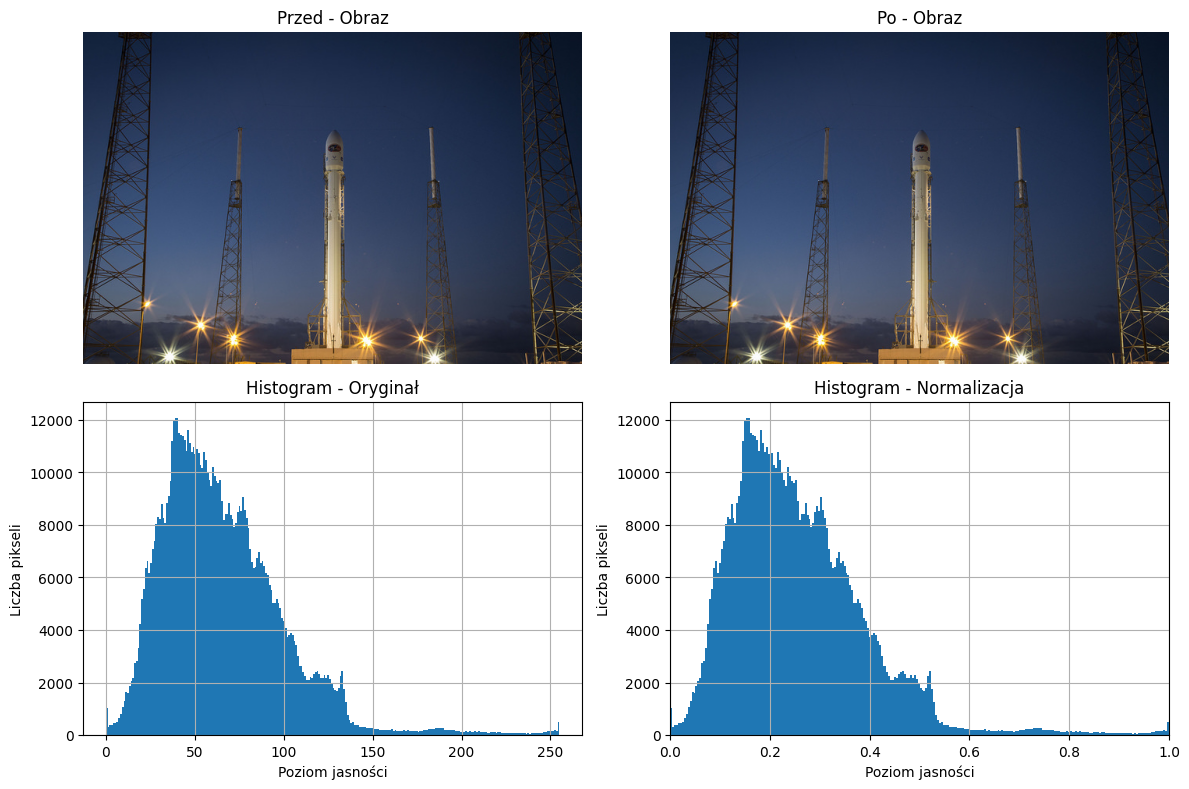

In [38]:
# 1. Normalize the image
norm = exposure.rescale_intensity(img, in_range='image', out_range=(0, 1))

# 2. Create the 2x2 grid (figsize adjusted for better proportions)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))


axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Przed - Obraz')
axes[0, 0].axis('off')

axes[0, 1].imshow(norm, cmap='gray')
axes[0, 1].set_title('Po - Obraz')
axes[0, 1].axis('off')



axes[1, 0].hist(img.ravel(), bins=256)
axes[1, 0].set_title('Histogram - Oryginał')
axes[1, 0].set_xlabel('Poziom jasności')
axes[1, 0].set_ylabel('Liczba pikseli')
axes[1, 0].grid()

axes[1, 1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1, 1].set_title('Histogram - Normalizacja')
axes[1, 1].set_xlabel('Poziom jasności')
axes[1, 1].set_ylabel('Liczba pikseli')
axes[1, 1].set_xlim(0, 1)
axes[1, 1].grid()

plt.tight_layout()
plt.show()

## 8. Wykonaj wyrównanie histogramu

Wykonaj wyrównanie histogramu:

```python
exposure.equalize_hist()
```

Wyświetl:

**obraz przed wyrównaniem | obraz po wyrównaniu**

Narysuj histogram obrazu wynikowego.

### Zastanów się

Jak zmienił się rozkład poziomów jasności?  
Czy szczegóły obrazu stały się bardziej widoczne?  
Czy histogram jest bardziej rozłożony w całym dostępnym zakresie?


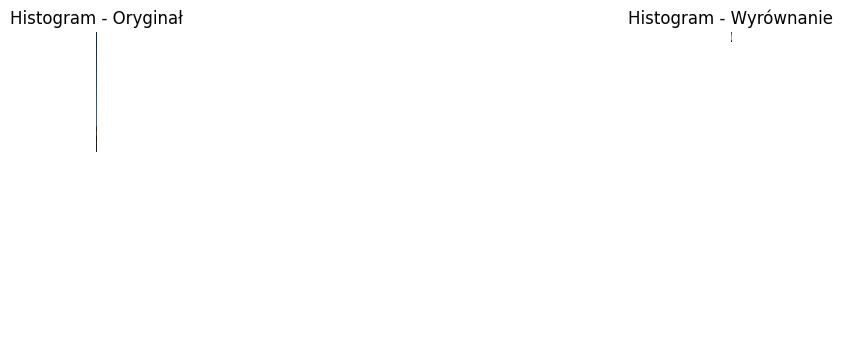

In [34]:
# Wykonaj wyrównanie histogramu i wyświetl wynik
# Histogram obrazu po wyrównaniu histogramu
eq = exposure.equalize_hist(img)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
titles = ['Oryginał', 'Wyrównanie']

# Wyświetlenie każdego obrazu w skali szarości z odpowiednim tytułem
for ax, im, t in zip(axes, [img, eq], titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')

axes[0].hist(img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

axes[1].hist(eq.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - Wyrównanie')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()


## 9. Porównaj wyniki

Na jednej figurze wyświetl:

```text
Oryginał | Normalizacja | Wyrównanie histogramu
```

Poniżej umieść odpowiadające im histogramy.

Porównaj wygląd obrazów i rozkład intensywności.

### Zastanów się nad różnicą pomiędzy normalizacją i wyrównaniem histogramu

Normalizacja przede wszystkim rozciąga zakres wartości, natomiast wyrównanie histogramu zmienia sposób rozmieszczenia intensywności w tym zakresie.


In [ ]:
# Porównaj obraz oryginalny, po normalizacji i po wyrównaniu histogramu

fig, axes = plt.subplots(3, 2, figsize=(12, 4))


